# Lab 5: Neural Network with Scikit-learn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NgKhiem69/datascience_course/blob/main/labs/05-neural-network/Neural%20network%20with%20Scikitlearn.ipynb)

**Nội dung:** huấn luyện mạng nơ-ron nhiều lớp (Multi-Layer Perceptron, `MLPClassifier`) để nhận dạng chữ số viết tay (bộ `digits` của scikit-learn), đánh giá mô hình, khảo sát kiến trúc mạng và so sánh với Logistic Regression. Ở cuối có ví dụ `MLPRegressor` trên dữ liệu `studyhours.csv` lấy từ GitHub.

## 0. Thiết lập môi trường (Google Colab)

Dữ liệu được đọc trực tiếp từ thư mục `data/` của repo GitHub qua đường dẫn *raw*, nên không cần upload file hay mount Google Drive.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Đường dẫn raw tới thư mục data trên GitHub
GITHUB_USER, GITHUB_REPO, BRANCH = "NgKhiem69", "datascience_course", "main"
DATA_URL = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/data"

def data_path(filename):
    """Trả về URL raw của một file trong thư mục data/ của repo."""
    return f"{DATA_URL}/{filename}"

# Kiểm tra đang chạy trên Colab hay máy local
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)
print("Data URL:", DATA_URL)

Running on Colab: False
Data URL: https://raw.githubusercontent.com/NgKhiem69/datascience_course/main/data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, mean_absolute_error, r2_score)

RANDOM_STATE = 42

## 1. Dữ liệu chữ số viết tay (digits)

1797 ảnh xám 8×8 pixel, mỗi pixel có giá trị 0–16 → 64 đặc trưng; nhãn là chữ số 0–9.

In [3]:
digits = load_digits()
X_d, y_d = digits.data, digits.target
print("X:", X_d.shape, " y:", y_d.shape)
print("Số mẫu mỗi lớp:", np.bincount(y_d))

X: (1797, 64)  y: (1797,)
Số mẫu mỗi lớp: [178 182 177 183 181 182 181 179 174 180]


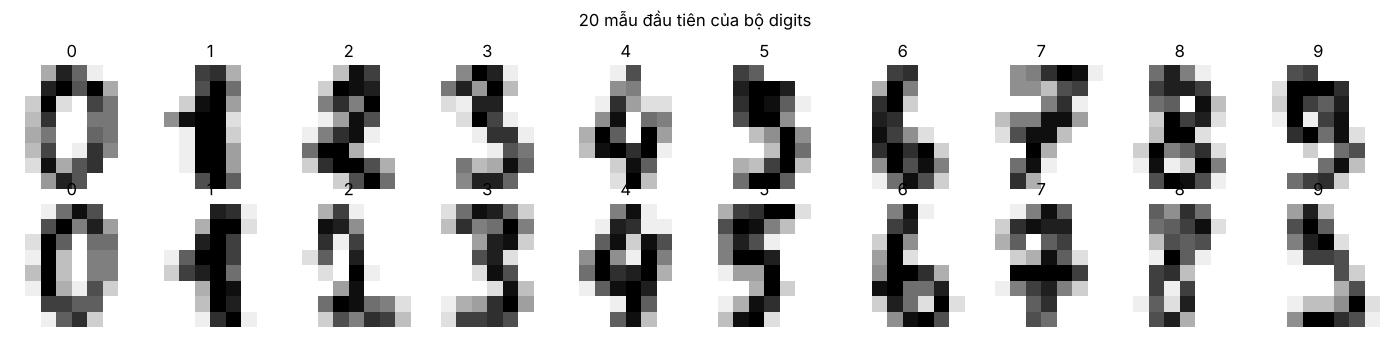

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.suptitle("20 mẫu đầu tiên của bộ digits")
plt.tight_layout()
plt.show()

## 2. Huấn luyện MLP

Kiến trúc: 64 input → 100 nơ-ron ẩn (ReLU) → 10 output (softmax). Dữ liệu được chuẩn hoá bằng `StandardScaler` vì mạng nơ-ron rất nhạy với thang đo đặc trưng.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_d, y_d, test_size=0.2, stratify=y_d, random_state=RANDOM_STATE)

mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=RANDOM_STATE),
)
mlp.fit(X_train, y_train)

print(f"Train accuracy: {100 * mlp.score(X_train, y_train):.2f}%")
print(f"Test accuracy : {100 * mlp.score(X_test, y_test):.2f}%")

Train accuracy: 100.00%
Test accuracy : 97.50%


Số vòng lặp (epochs): 150
Số lớp (kể cả input/output): 3
Kích thước ma trận trọng số: [(64, 100), (100, 10)]
Tổng số tham số: 7510


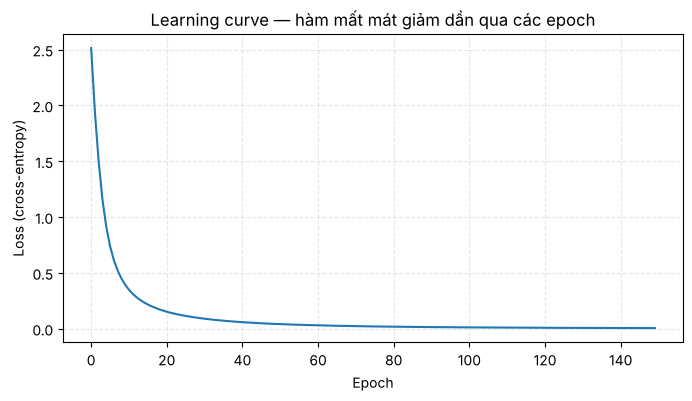

In [6]:
net = mlp.named_steps["mlpclassifier"]
print("Số vòng lặp (epochs):", net.n_iter_)
print("Số lớp (kể cả input/output):", net.n_layers_)
print("Kích thước ma trận trọng số:", [w.shape for w in net.coefs_])
n_params = sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)
print("Tổng số tham số:", n_params)

plt.figure(figsize=(8, 4))
plt.plot(net.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Loss (cross-entropy)")
plt.title("Learning curve — hàm mất mát giảm dần qua các epoch")
plt.grid(linestyle="--", alpha=0.3)
plt.show()

## 3. Đánh giá chi tiết

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.917     0.917     0.917        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      0.972     0.972     0.972        36
           5      0.974     1.000     0.987        37
           6      1.000     1.000     1.000        36
           7      1.000     1.000     1.000        36
           8      0.939     0.886     0.912        35
           9      0.946     0.972     0.959        36

    accuracy                          0.975       360
   macro avg      0.975     0.975     0.975       360
weighted avg      0.975     0.975     0.975       360



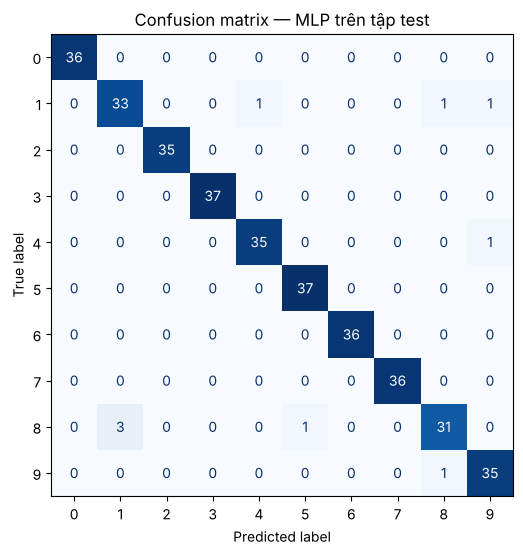

In [7]:
y_pred = mlp.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion matrix — MLP trên tập test")
plt.show()

Số mẫu đoán sai: 9 / 360


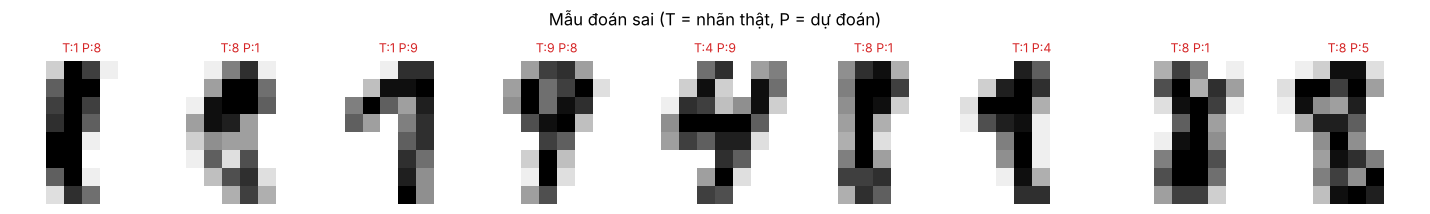

In [8]:
# Các mẫu bị đoán sai
wrong = np.where(y_pred != y_test)[0]
print("Số mẫu đoán sai:", len(wrong), "/", len(y_test))
n_show = min(len(wrong), 10)
if n_show:
    fig, axes = plt.subplots(1, n_show, figsize=(1.6 * n_show, 2.2))
    axes = np.atleast_1d(axes)
    for ax, idx in zip(axes, wrong[:n_show]):
        ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"T:{y_test[idx]} P:{y_pred[idx]}", fontsize=9, color="#d62728")
        ax.axis("off")
    plt.suptitle("Mẫu đoán sai (T = nhãn thật, P = dự đoán)")
    plt.tight_layout()
    plt.show()

## 4. Ảnh hưởng của kiến trúc mạng

Thử nhiều cấu hình lớp ẩn khác nhau và so sánh độ chính xác, thời gian.

In [9]:
import time

architectures = [(10,), (50,), (100,), (200,), (100, 50), (128, 64, 32)]
results = []
for hidden in architectures:
    model = make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=hidden, max_iter=1000, random_state=RANDOM_STATE))
    t0 = time.time()
    model.fit(X_train, y_train)
    results.append({
        "hidden_layers": str(hidden),
        "train_acc": model.score(X_train, y_train),
        "test_acc": model.score(X_test, y_test),
        "epochs": model.named_steps["mlpclassifier"].n_iter_,
        "time_s": time.time() - t0,
    })
arch_df = pd.DataFrame(results).set_index("hidden_layers").round(4)
arch_df

,train_acc,test_acc,epochs,time_s
hidden_layers,,,,
"(10,)",0.9986,0.9500,396,1.5454
"(50,)",1.0000,0.9722,186,1.1497
"(100,)",1.0000,0.9750,150,0.9037
"(200,)",1.0000,0.9889,112,1.0897
"(100, 50)",1.0000,0.9778,92,0.9982
"(128, 64, 32)",1.0000,0.9778,70,1.1993


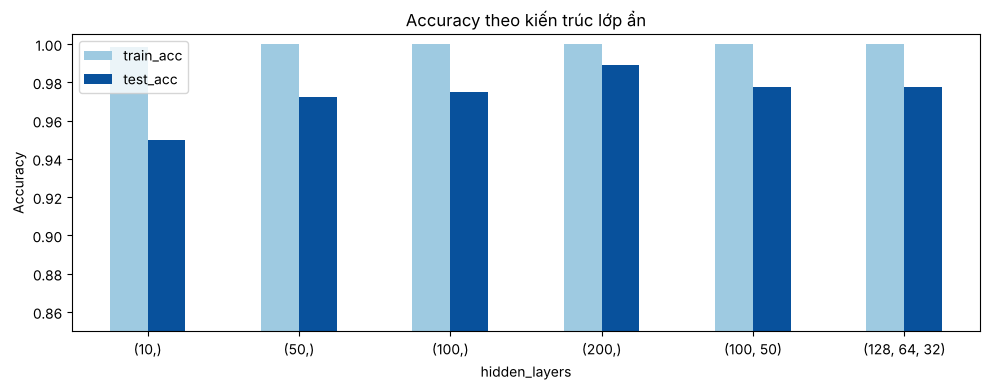

In [10]:
ax = arch_df[["train_acc", "test_acc"]].plot.bar(figsize=(10, 4), rot=0, color=["#9ecae1", "#08519c"])
ax.set_ylim(0.85, 1.005)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy theo kiến trúc lớp ẩn")
plt.tight_layout()
plt.show()

## 5. Tìm siêu tham số bằng GridSearchCV

`alpha` là hệ số điều chuẩn L2 (chống overfitting), `learning_rate_init` là tốc độ học ban đầu.

In [11]:
param_grid = {
    "mlpclassifier__hidden_layer_sizes": [(64,), (128,), (128, 64)],
    "mlpclassifier__alpha": [1e-4, 1e-3, 1e-2],
    "mlpclassifier__learning_rate_init": [1e-3, 1e-2],
}
grid = GridSearchCV(
    make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=RANDOM_STATE)),
    param_grid, cv=3, n_jobs=-1, scoring="accuracy",
)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")
print(f"Test accuracy   : {grid.score(X_test, y_test):.4f}")

Best params: {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (64,), 'mlpclassifier__learning_rate_init': 0.001}
Best CV accuracy: 0.9708
Test accuracy   : 0.9806


## 6. So sánh với Logistic Regression

In [12]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logreg.fit(X_train, y_train)

pd.DataFrame({
    "Model": ["Logistic Regression", "MLP (100,)", "MLP (GridSearch best)"],
    "Test accuracy": [logreg.score(X_test, y_test), mlp.score(X_test, y_test), grid.score(X_test, y_test)],
}).set_index("Model").round(4)

,Test accuracy
Model,
Logistic Regression,0.9722
"MLP (100,)",0.9750
MLP (GridSearch best),0.9806


## 7. MLPRegressor với dữ liệu từ GitHub — dự đoán điểm thi từ số giờ học

Linear Regression   MAE = 4.82   R² = 0.877
MLP Regressor       MAE = 4.19   R² = 0.906


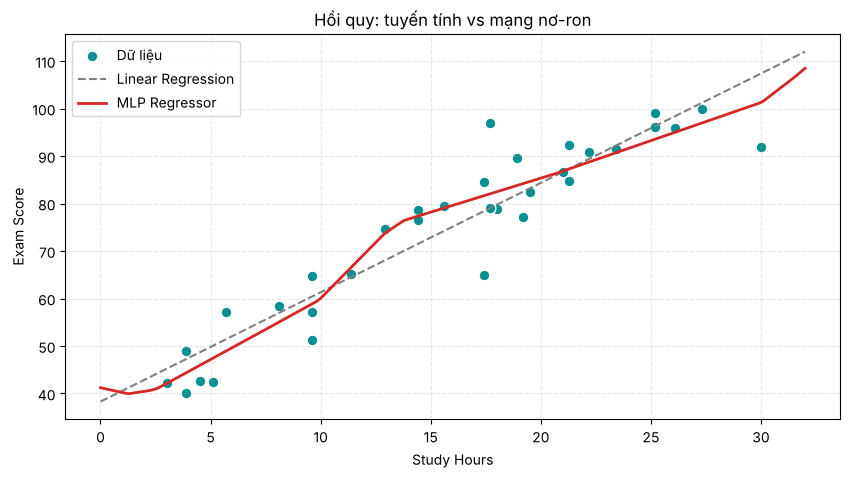

In [13]:
sh = pd.read_csv(data_path("studyhours.csv"))
Xs, ys = sh[["Study Hours"]].to_numpy(), sh["Exam Score"].to_numpy()

lin = LinearRegression().fit(Xs, ys)
mlp_reg = make_pipeline(StandardScaler(),
                        MLPRegressor(hidden_layer_sizes=(16, 16), max_iter=5000,
                                     alpha=1e-2, random_state=RANDOM_STATE)).fit(Xs, ys)

for name, m in [("Linear Regression", lin), ("MLP Regressor", mlp_reg)]:
    p = m.predict(Xs)
    print(f"{name:18}  MAE = {mean_absolute_error(ys, p):.2f}   R² = {r2_score(ys, p):.3f}")

x_grid = np.linspace(0, 32, 200).reshape(-1, 1)
plt.figure(figsize=(10, 5))
plt.scatter(Xs, ys, color="#088F8F", edgecolor="white", s=60, label="Dữ liệu")
plt.plot(x_grid, lin.predict(x_grid), "--", color="gray", label="Linear Regression")
plt.plot(x_grid, mlp_reg.predict(x_grid), color="#d62728", linewidth=2, label="MLP Regressor")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Hồi quy: tuyến tính vs mạng nơ-ron")
plt.legend()
plt.grid(linestyle="--", alpha=0.3)
plt.show()

Lưu ý: chỉ có 33 mẫu nên đánh giá trên chính tập huấn luyện; MLP có thể học được đường cong (điểm bão hoà gần 100) nhưng cũng dễ overfit với dữ liệu nhỏ như vậy.

## Tổng kết

- MLP một lớp ẩn 100 nơ-ron đạt độ chính xác rất cao trên bộ digits.
- Tăng số nơ-ron/lớp ẩn không phải lúc nào cũng tốt hơn rõ rệt nhưng tốn thời gian hơn.
- Với dữ liệu nhỏ, đơn giản như digits, Logistic Regression cũng đã rất mạnh — mạng nơ-ron phát huy ưu thế rõ hơn trên dữ liệu lớn và quan hệ phi tuyến phức tạp.